In [1]:
import numpy as np
import torch as tc
import numpy.random as rd
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import argparse
import linear_crossbar


from circuit_solver import circuit as ct
from circuit_solver import elements as es
from circuit_solver import utils
from circuit_solver.learning import CoupledLearning, SymmetricCoupledLearning, CLTrainingConfig, CLTestingConfig, CoupledLearningEtaZero
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'

In [2]:
seed = 0    # RNG seed for model and data generation
N = 5
M = 3
eta_values = [0., 1]

N_eta = len(eta_values)
cb_ = [linear_crossbar.new(N=N, M=M, seed=seed) for n in range(N_eta)]
for a in cb_:
    a.model.set_absorbing()

In [3]:
P = 50          # number of samples
alpha_power = 1.0  # power-law exponent for eigenvalues: λ_i ∝ i^(-α)

dims = N + M
eigenvalues = (np.arange(1, dims + 1, dtype=float)) ** (-alpha_power)

# Random orthogonal basis via QR
rng = np.random.default_rng(seed)
Q, _ = np.linalg.qr(rng.standard_normal((dims, dims)))
cov = Q @ np.diag(eigenvalues) @ Q.T

Z = rng.multivariate_normal(np.zeros(dims), cov, size=P).astype(np.float32)
X_data = Z[:, :N]
Y_data = 1 * Z[:, N:]

print(f"X_data: {X_data.shape},  Y_data: {Y_data.shape}")

X_data: (50, 5),  Y_data: (50, 3)


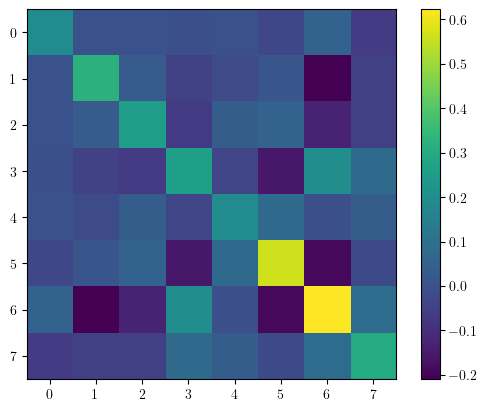

In [4]:
plt.imshow(cov)
plt.colorbar()
# plt.axline(N, color='white')

In [5]:
# alpha = 0.1
# N_batches = 1500
alpha = 0.05
N_batches = 3000
batch_size = P

histories = []
for cb, eta in zip(cb_, eta_values):
    cb.model.reset()
    config = CLTrainingConfig(
        batch_size=batch_size,
        N_batches=N_batches,
        alpha=alpha,
        eta=eta,
    )
    learner = CoupledLearningEtaZero if eta == 0 else CoupledLearning
    print(f"Training  eta={eta}  ({learner.__name__})")
    histories.append(learner(X_data, Y_data, cb.model, config))

Training  eta=0.0  (CoupledLearningEtaZero)


100%|██████████| 3000/3000 [00:05<00:00, 556.88it/s]


Training  eta=1  (CoupledLearning)


100%|██████████| 3000/3000 [00:03<00:00, 937.94it/s] 


# Note on $\eta$ convention

The convention used in the code base (`circuit-solver`) is that positive $\eta$ pushes the outputs towards the desired target state. In the paper, the opposite sign convention is used. This is the reason why the plots below have a mismatch between label and variable definition.

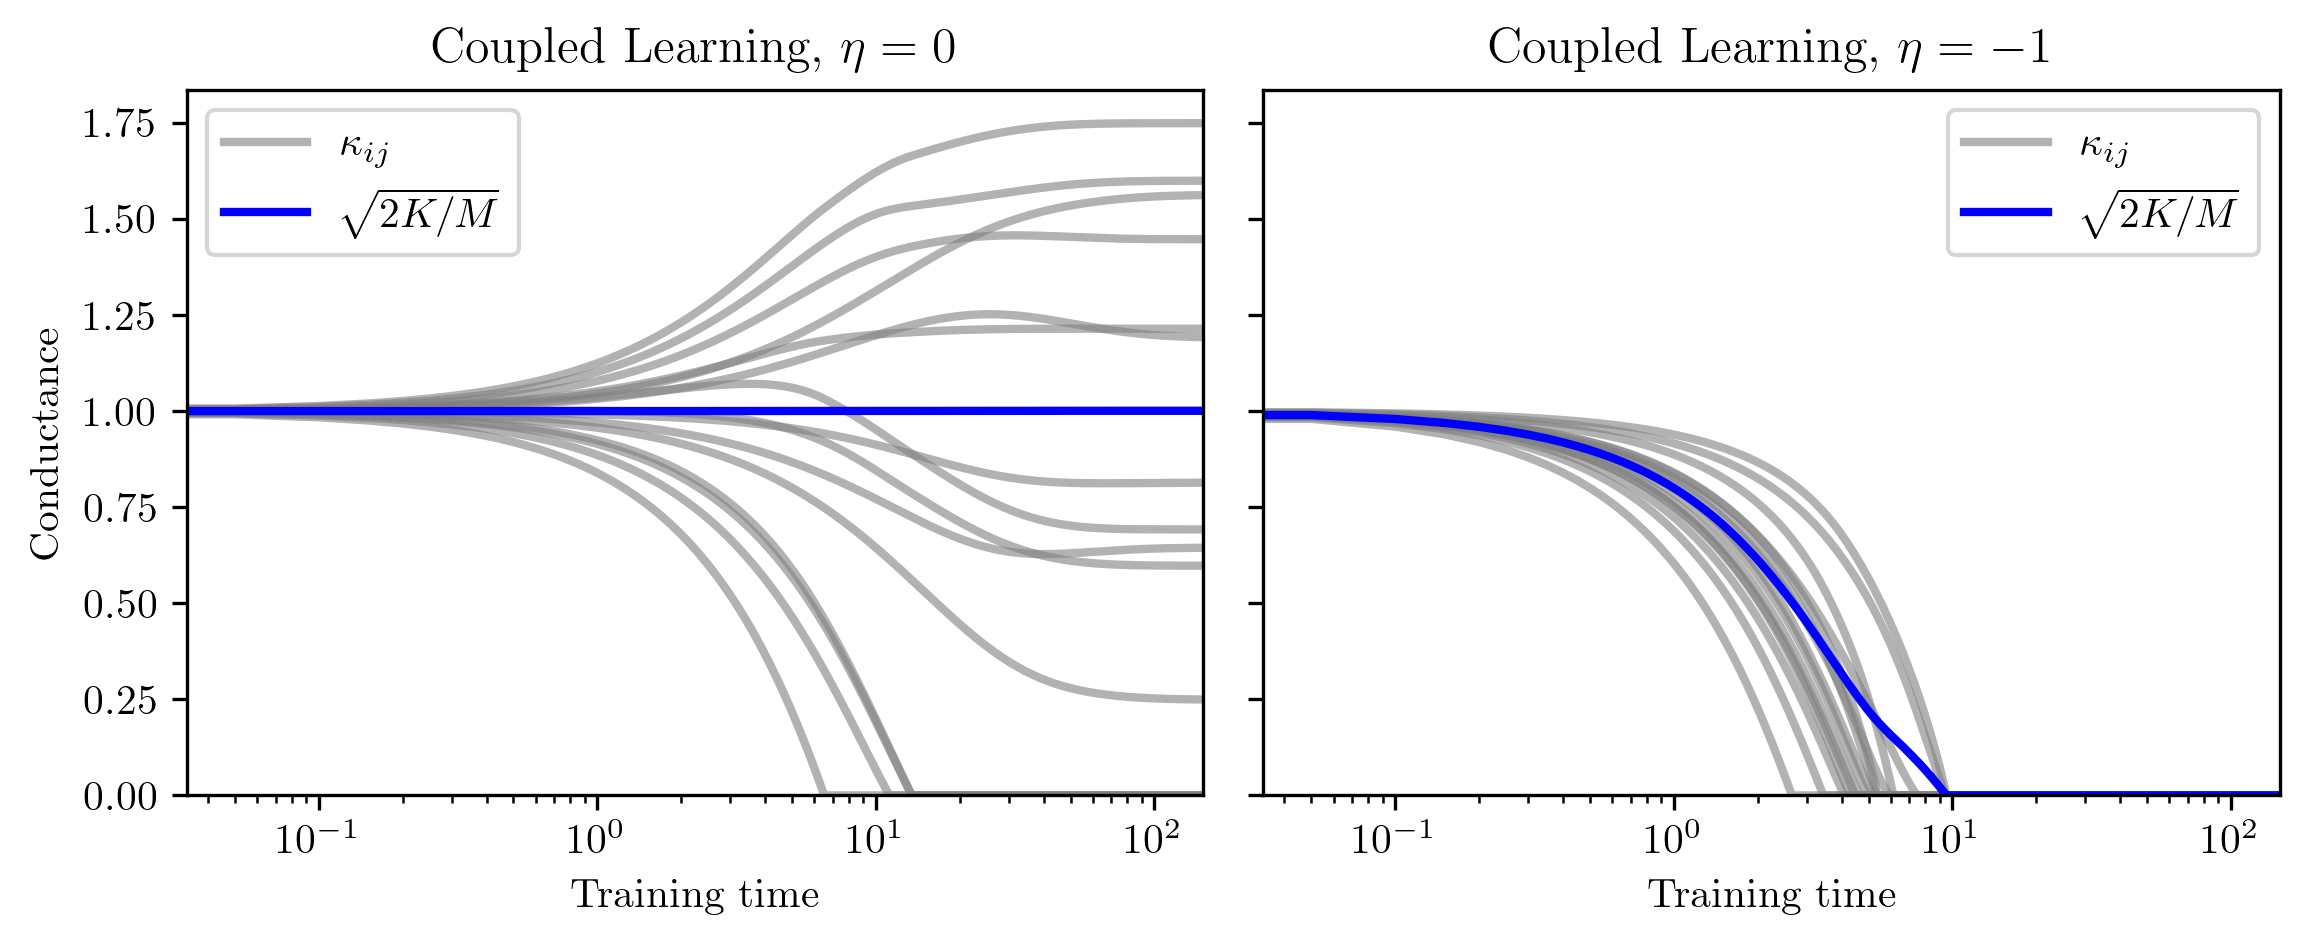

In [6]:
sz = 1.3
fig, axes = plt.subplots(1, N_eta, figsize=(3 * sz * N_eta, 2.5 * sz), dpi=300, sharey=True)

color = (0.5,0.5,0.5)
lw = 2
for ax, history, eta in zip(axes, histories, eta_values):
    G = history['out']   # shape (N*M, N_batches+1): each row is one conductance trajectory
    steps = np.arange(G.shape[1])
    for g in G:
        K = np.sqrt(np.mean(g**2, axis=1))
    
        ax.semilogx(steps * alpha, g, linewidth=lw, alpha=0.6, color=color)
        ax.semilogx([], [], linewidth=lw, alpha=0.6, color=color, label='$\\kappa_{ij}$')
        ax.semilogx(steps * alpha, K, linewidth=lw, color='blue', label='$\\sqrt{2K/M}$')
        
        # ax.plot(steps * alpha, g, linewidth=lw, alpha=0.6, color=color)
        # ax.plot([], [], linewidth=lw, alpha=0.6, color=color, label='$\\kappa_{ij}$')
        # ax.plot(steps * alpha, K, linewidth=lw, color='blue', label='$\\sqrt{2K/M}$')

    ax.set_ylim(0)
    # ax.set_xlim(0,20)
    ax.set_xlim(xmax=steps[-1]*alpha)
    ax.set_xlabel('Training time')
    lbl = -eta if eta != 0 else 0
    ax.set_title(f'Coupled Learning, $\\eta = {lbl}$')
    ax.legend()

axes[0].set_ylabel('Conductance')
plt.tight_layout()
plt.show()